# moBRCA-net-Inspired Attention-Based Breast Cancer Representation

This notebook explores an attention-based breast-cancer-specific transcriptomic representation inspired by **moBRCA-net**.

moBRCA-net is **not** a variational autoencoder. It is an interpretable attention-based deep learning framework originally designed for breast cancer subtype classification using multi-omics data.

The original moBRCA-net framework integrates gene expression, DNA methylation and microRNA expression, applies self-attention to each omics modality, and transforms features into new representations informed by learned feature importance.

We use a **transcriptomics-only adaptation** for the institutional dataset. The representation model is trained externally on METABRIC breast cancer gene-expression data using PAM50 subtype labels, and the trained encoder is then applied to the institutional oligometastatic/polymetastatic transcriptomic cohort.

The resulting latent/attention-based transcriptomic representation is evaluated using the same nested cross-validation framework and macro-F1 model-selection criterion as the other transcriptomic representations.

## Scope

This is a moBRCA-net-inspired gene-expression attention representation, not a full reproduction of the original multi-omics model. The transcriptomics-only adaptation tests whether a representation learned from external breast cancer subtype structure transfers to institutional oligo/poly classification. The frozen embedding contains 100 latent dimensions.


In [1]:
# Display precision only; analytical values and saved artifacts stay unchanged.
from pathlib import Path as _DisplayPath
import sys as _display_sys
_display_root = _DisplayPath.cwd()
while not (_display_root / "scripts").is_dir() and _display_root != _display_root.parent:
    _display_root = _display_root.parent
if str(_display_root) not in _display_sys.path:
    _display_sys.path.insert(0, str(_display_root))
from scripts.OligoPolyThesis.utils_ml_oligopoly import thesis_display, thesis_print

import json
import joblib
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
import warnings
from IPython.display import display, Markdown
ROOT = Path.cwd()
while not (ROOT / "scripts").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from scripts.OligoPolyThesis.utils_ml_oligopoly import (
    set_global_seed, split_transcriptomics_features_target_metadata,
    prepare_attention_canonical, build_attention_classifiers, build_mobrcanet_expression_attention_model,
    begin_metabric_encoder_run, metabric_encoder_operational_callbacks, complete_metabric_encoder_run,
    load_metabric_reviewed_scores, metabric_source_fingerprint, plot_classification_training_history,
    validate_tpm_oof, rank_tpm_inner_scores, tpm_pooled_oof_metrics,
    evaluate_metabric_latent_representation, summarise_representation_results,
    extract_fitted_tpm_feature_rankings,
    plot_roc_curves, plot_precision_recall_curves, plot_confusion_matrix, plot_calibration_curve,
    plot_metric_boxplots,
    compute_representation_silhouette, plot_umap_representation,
    run_nested_flaml_metabric_latent, fit_metabric_latent_flaml,
)
from scripts.OligoPolyThesis.utils_ml_oligopoly import (
    plot_latent_outer_scores,
    plot_latent_train_test,
    select_mean_inner_combination,
    display_interpretation,
)
RANDOM_STATE = 42
set_global_seed(RANDOM_STATE)


## External source

Expression comes from the full cBioPortal METABRIC log2-intensity matrix. Five-class PAM50 labels are joined by exact sample ID from the original IntegrativeVAEs file; its reduced expression features are not used. The downstream results below concern the attention representation.


In [2]:
project_root = Path('/mnt/data3/MCPP-Breast')
external_root = project_root / 'Machine-Learning-Models-poly_vs_oligo/External-Data'
source_dir = external_root / 'cBioPortal/brca_metabric'
metabric_expression_path = source_dir / 'data_mrna_illumina_microarray.txt'
metadata_path = source_dir / 'meta_mrna_illumina_microarray.txt'
study_path = source_dir / 'meta_study.txt'
label_path = external_root / 'IntegrativeVAEs/IntegrativeVAEs-master/data/MBdata_33CLINwMiss_1KfGE_1KfCNA.csv'
institutional_expression_path = project_root / 'Transcriptomic-Data/Preprocessed/transcriptomics_oligo_poly_log2_tpm_preprocessed.csv'
gene_mapping_path = institutional_expression_path.with_name('transcriptomics_feature_name_mapping.csv')
source_paths = [metabric_expression_path, metadata_path, study_path, label_path, institutional_expression_path, gene_mapping_path]
output_dir = project_root / 'Machine-Learning-Models-poly_vs_oligo/Transcriptomics-BC-Specific-Representations/moBRCA-net-Attention/canonical-16950'
preparation_manifest = output_dir / 'attention_preparation.json'
mobrcanet_repo_dir = external_root / 'moBRCA-net'


## Representation Configuration

We select the most variable shared METABRIC genes, train a supervised attention model on METABRIC PAM50 subtype labels, and use the learned hidden representation as the breast-cancer-specific transcriptomic embedding.

In [3]:
N_TOP_VARIABLE_GENES = 1000
LATENT_DIM = 100
HIDDEN_DIM = 256
DROPOUT_RATE = 0.3
VALIDATION_FRACTION = 0.2
BATCH_SIZE = 32
EPOCHS = 300
PATIENCE = 30
LEARNING_RATE = 1e-3
RUN_PREPARE_SOURCE = True
RUN_ATTENTION_ENCODER = False
RUN_NESTED_CV = True
RUN_FLAML = False
RUN_FULL_COHORT_FLAML = False
RUN_INTEGRATED_GRADIENTS = False
RUN_EXPLORATORY = False
FLAML_TIME_BUDGET_SECONDS = 120
REPRESENTATION_NAME = 'metabric_cbioportal_mobrcanet_attention_latent100'
completed_dir = output_dir / f'{REPRESENTATION_NAME}_completed'
latent_scores_path = completed_dir / f'transcriptomics_{REPRESENTATION_NAME}_scores.csv'
prepared = None
latent_scores_df = None
history_df = None
attention_encoder = None
attention_scores_df = None


## Inspect moBRCA-net Repository Files

The original moBRCA-net repository is inspected for documentation and provenance, but the model below is implemented as a transcriptomics-only adaptation.

This is because the original repository expects pre-prepared multi-omics input files, whereas the current pipeline only projects transcriptomic TPM data.

In [4]:
## Inspect moBRCA-net Repository Files ##

if mobrcanet_repo_dir.exists():
    repo_files = sorted([
        path.relative_to(mobrcanet_repo_dir)
        for path in mobrcanet_repo_dir.rglob("*")
        if path.is_file() and ".git" not in path.parts
    ])

    thesis_print("Number of non-git files in moBRCA-net repo:")
    thesis_print(len(repo_files))

    thesis_print("\nRepository files:")
    for path in repo_files[:80]:
        thesis_print(path)
else:
    thesis_print("moBRCA-net repository directory not found.")


Number of non-git files in moBRCA-net repo:
6

Repository files:
LICENSE
README.md
cvae_generator.py
fig1_v7.png
moBRCA-net.py
run_moBRCA-net.sh


## External PAM50 labels

Exact sample-ID matching preserves the five original PAM50 classes: Basal, Her2, LumA, LumB and Normal. Unknown labels are excluded. Duplicate IDs, unexpected classes or unmatched expression samples stop preparation. CLAUDIN_SUBTYPE is not substituted.


In [5]:
# Source and PAM50 validation are performed together in canonical preparation (cell 17).


## Load Institutional Oligo/Poly TPM Data

We load the institutional transcriptomic matrix and separate the transcriptomic features, oligo/poly target, and metadata.

The target is `Polymetastatic`, with 0 corresponding to oligometastatic and 1 corresponding to polymetastatic disease.

In [6]:
## Load Institutional Oligo/Poly TPM Data ##

try:
    institutional_expression_df, y, metadata_df = (
        split_transcriptomics_features_target_metadata(
            transcriptomics_path=institutional_expression_path,
            target_col="Polymetastatic",
            feature_prefix="transcriptomics__",
        )
    )
except TypeError:
    institutional_transcriptomics_df = pd.read_csv(institutional_expression_path)
    output = split_transcriptomics_features_target_metadata(
        transcriptomics_df=institutional_transcriptomics_df,
        target_col="Polymetastatic",
        feature_prefix="transcriptomics__",
    )
    institutional_expression_df, y, metadata_df = output[:3]

if "sample_id_normalised" not in metadata_df.columns:
    raise ValueError("metadata_df must contain 'sample_id_normalised'.")

# Preserve sample IDs as the expression matrix index. Without this, latent-score
# outputs get a numeric RangeIndex and the later merge with metadata becomes empty.
institutional_sample_ids = metadata_df["sample_id_normalised"].astype(str).values

if institutional_expression_df.shape[0] != len(institutional_sample_ids):
    raise ValueError(
        "Number of institutional expression rows does not match metadata sample IDs."
    )

institutional_expression_df = institutional_expression_df.copy()
institutional_expression_df.index = institutional_sample_ids

thesis_print("Institutional expression matrix shape:")
thesis_print(institutional_expression_df.shape)

thesis_print("\nTarget distribution:")
thesis_print(y.value_counts().sort_index())

thesis_print("\nFirst institutional sample IDs:")
thesis_print(institutional_expression_df.index[:10].tolist())

thesis_display(institutional_expression_df.head())
thesis_display(metadata_df.head())


Institutional expression matrix shape:
(139, 18260)

Target distribution:
Polymetastatic
0    54
1    85
Name: count, dtype: int64

First institutional sample IDs:
['101B', '108B', '10B', '110B', '115B', '11B', '128B', '12B', '133B', '134B']


,transcriptomics__ENSG00000000003,transcriptomics__ENSG00000000005,transcriptomics__ENSG00000000419,transcriptomics__ENSG00000000457,transcriptomics__ENSG00000000460,transcriptomics__ENSG00000000938,transcriptomics__ENSG00000000971,transcriptomics__ENSG00000001036,transcriptomics__ENSG00000001084,transcriptomics__ENSG00000001167,...,transcriptomics__ENSG00000289721,transcriptomics__ENSG00000289746,transcriptomics__ENSG00000289762,transcriptomics__ENSG00000290292,transcriptomics__ENSG00000291237,transcriptomics__ENSG00000291307,transcriptomics__ENSG00000291309,transcriptomics__ENSG00000291316,transcriptomics__ENSG00000291317,transcriptomics__ENSG00000293543
101B,3.575,0.000,7.108,5.442,5.503,0.983,5.494,6.254,5.513,5.626,...,0.000,0.000,0.000,3.874,9.325,0.0,6.060,5.032,4.841,0.0
108B,4.447,0.000,6.674,3.731,4.848,3.864,5.304,4.990,6.267,4.868,...,0.977,2.580,4.518,4.208,6.840,0.0,5.751,1.311,4.119,0.0
10B,4.698,0.000,5.981,4.556,5.729,2.916,5.427,5.085,5.098,6.475,...,2.668,1.598,0.000,5.191,7.456,0.0,5.609,0.000,5.453,0.0
110B,4.242,0.000,7.116,3.620,4.495,3.741,6.813,5.631,6.462,3.759,...,0.000,3.426,0.000,4.180,8.730,0.0,5.954,0.000,3.619,0.0
115B,3.436,3.174,6.883,4.456,5.580,4.363,7.264,5.643,5.487,5.286,...,3.117,4.866,0.000,4.905,7.681,0.0,5.292,3.756,3.962,0.0


,sample_id_original,sample_id_normalised,transcriptomics_source,metastatic_group,Polymetastatic
0,101B.WTS_S57,101B,rnaseq_tpm_norm.txt,oligometastatic,0
1,108B.WTS_S64,108B,rnaseq_tpm_norm.txt,oligometastatic,0
2,10B.WTS_S24,10B,rnaseq_tpm_norm.txt,oligometastatic,0
3,110B.WTS_S66,110B,rnaseq_tpm_norm.txt,oligometastatic,0
4,115B.WTS_S2,115B,rnaseq_tpm_norm.txt,oligometastatic,0


## Gene identities

The shared schema contains 16,950 biological genes. Resolved duplicate METABRIC measurements are averaged per sample on the supplied log2 scale. Institutional gene mappings are unique and are not aggregated.


In [7]:
gene_mapping_df = pd.read_csv(gene_mapping_path)


## Training-only external preparation

The PAM50-stratified 80:20 split uses seed 42. Imputation medians, variance selection of 1,000 genes and standardisation are fitted on external training samples only. Institutional data are transformed with frozen parameters. Cross-platform microarray/RNA-seq differences remain a transfer limitation. The inherited institutional full-cohort X-only prevalence filter is not corrected by external training.


In [8]:
if RUN_PREPARE_SOURCE or RUN_ATTENTION_ENCODER or RUN_INTEGRATED_GRADIENTS:
    prepared = prepare_attention_canonical(metabric_expression_path, metadata_path, study_path,
        label_path, institutional_expression_df, gene_mapping_df, output_dir, source_paths, RANDOM_STATE)
    thesis_display(prepared['provenance']['pam50'])


{'canonical_samples': 1980,
 'validated_samples': 1974,
 'unmatched_samples': [],
 'duplicate_sample_ids': [],
 'conflicting_labels': [],
 'excluded_unknown_samples': ['MB-2778',
  'MB-4697',
  'MB-4224',
  'MB-6077',
  'MB-5339',
  'MB-7237'],
 'classes': ['Basal', 'Her2', 'LumA', 'LumB', 'Normal'],
 'class_counts': {'LumA': 718,
  'LumB': 488,
  'Basal': 329,
  'Her2': 240,
  'Normal': 199},
 'label_source': {'/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/External-Data/IntegrativeVAEs/IntegrativeVAEs-master/data/MBdata_33CLINwMiss_1KfGE_1KfCNA.csv': {'sha256': '4d8c56dd8f01440782174071baa3b9d78a5630edfabe4f2663496f83bcc86b0c',
   'bytes': 22397867}}}

## Prepare External Training Data

The attention model is trained on METABRIC PAM50 subtype labels.

The scaler is fitted only on the METABRIC training split and then applied to the METABRIC validation split and institutional cohort.

In [9]:
if prepared is not None:
    label_encoder = LabelEncoder()
    encoded = label_encoder.fit_transform(prepared['labels'])
    scaler = prepared['scaler']
    train, val = prepared['train'], prepared['val']
    X_metabric_train_scaled = scaler.transform(prepared['external'].iloc[train]).astype(np.float32)
    X_metabric_val_scaled = scaler.transform(prepared['external'].iloc[val]).astype(np.float32)
    X_metabric_full_scaled = scaler.transform(prepared['external']).astype(np.float32)
    X_institutional_scaled = scaler.transform(prepared['institutional']).astype(np.float32)
    y_metabric_train, y_metabric_val = encoded[train], encoded[val]
    n_classes = len(label_encoder.classes_)
    class_weight_dict = dict(enumerate(compute_class_weight(class_weight='balanced', classes=np.arange(n_classes), y=y_metabric_train)))


## Build moBRCA-net-Inspired Gene-Expression Attention Model

The transcriptomics-only model uses sigmoid feature gates over gene-expression inputs, followed by a hidden embedding for external PAM50 classification. Each gate takes a value between zero and one without imposing a sum-to-one constraint across genes. After external training, the frozen 100-dimensional hidden embedding represents institutional samples; institutional oligo/poly labels do not train the encoder.


In [10]:
if RUN_ATTENTION_ENCODER:
    input_dim = X_metabric_train_scaled.shape[1]

    attention_classifier, attention_encoder, attention_weights_model = (
        build_mobrcanet_expression_attention_model(
            input_dim=input_dim,
            n_classes=n_classes,
            latent_dim=LATENT_DIM,
            hidden_dim=HIDDEN_DIM,
            dropout_rate=DROPOUT_RATE,
            learning_rate=LEARNING_RATE,
        )
    )

    attention_classifier.summary()


## Train Attention Model on METABRIC PAM50 Subtypes

The attention model is trained only on METABRIC breast cancer samples using PAM50 subtype labels.

The institutional oligo/poly cohort is not used during this representation-learning stage.

In [11]:
if RUN_ATTENTION_ENCODER:
    attention_run = begin_metabric_encoder_run(output_dir, REPRESENTATION_NAME, prepared['provenance'])
    ## Train Attention Model on METABRIC PAM50 Subtypes ##

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True,
    )

    reduce_lr = keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=10,
        min_lr=1e-5,
    )

    history = attention_classifier.fit(
        X_metabric_train_scaled,
        y_metabric_train,
        validation_data=(X_metabric_val_scaled, y_metabric_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=[early_stopping, reduce_lr] + metabric_encoder_operational_callbacks(attention_run),
        class_weight=class_weight_dict,
        verbose=1,
    )

    history_df = pd.DataFrame(history.history)

    thesis_display(history_df.tail())


## Inspect Training History

We inspect the METABRIC training and validation curves to check whether the attention model learned the PAM50 subtype task and whether there is evidence of overfitting.

In [12]:
if RUN_ATTENTION_ENCODER:
    plot_classification_training_history(history_df, title_prefix="moBRCA-net-Inspired Attention Model")


## Project Institutional Samples into the Attention-Based Representation

After training the attention model on METABRIC PAM50 classification, we use the encoder to project institutional oligo/poly samples into the learned latent representation.

This produces one latent feature vector per institutional sample.

In [13]:
if RUN_ATTENTION_ENCODER:
    latent = attention_encoder.predict(X_institutional_scaled, batch_size=BATCH_SIZE)
    latent_scores_df = pd.DataFrame(latent, columns=[f'{REPRESENTATION_NAME}_latent_{i+1}' for i in range(LATENT_DIM)])
    latent_scores_df.insert(0, 'sample_id_normalised', institutional_expression_df.index)
else:
    latent_scores_df = load_metabric_reviewed_scores(latent_scores_path,
        completed_dir / f'{REPRESENTATION_NAME}_metadata.json', source_paths, preparation_manifest)


## Gene-level gating

Mean and SD of sigmoid gates describe external and institutional expression-dependent gating. These are not downstream classifier coefficients or causal biomarkers.


In [14]:
if RUN_ATTENTION_ENCODER:
    gates = attention_weights_model.predict(X_institutional_scaled, batch_size=BATCH_SIZE)
    external_gates = attention_weights_model.predict(X_metabric_full_scaled, batch_size=BATCH_SIZE)
    attention_scores_df = pd.DataFrame({'gene_name': prepared['institutional'].columns,
        'mean_attention': gates.mean(axis=0), 'std_attention': gates.std(axis=0),
        'mean_external_attention': external_gates.mean(axis=0), 'std_external_attention': external_gates.std(axis=0)})
    thesis_display(attention_scores_df.sort_values('mean_attention', ascending=False).head(30))


## Save Attention-Based Representation Outputs

We save the trained attention classifier, the encoder used to generate latent representations, the selected genes, attention scores, training history, and institutional latent scores.

The latent-score CSV is the main file required for downstream nested cross-validation.

In [15]:
if RUN_ATTENTION_ENCODER:
    artifact_dir = attention_run['attempt'] / 'artifacts'
    attention_encoder.save(artifact_dir / f'{REPRESENTATION_NAME}_z_mean_encoder.keras')
    attention_classifier.save(artifact_dir / f'{REPRESENTATION_NAME}_classifier.keras')
    attention_weights_model.save(artifact_dir / f'{REPRESENTATION_NAME}_attention_weights_model.keras')
    history_df.to_csv(artifact_dir / f'{REPRESENTATION_NAME}_training_history.csv', index=False)
    latent_scores_df.to_csv(artifact_dir / f'transcriptomics_{REPRESENTATION_NAME}_scores.csv', index=False)
    attention_scores_df.to_csv(artifact_dir / 'attention_gene_gates.csv', index=False)
    prepared['gene_map'].to_csv(artifact_dir / 'selected_gene_mapping.csv', index=False)
    joblib.dump(joblib.load(output_dir / 'attention_preprocessing.joblib'), artifact_dir / 'external_scaler.joblib')
    metadata = {'source_provenance': prepared['provenance'], 'pam50_classes': label_encoder.classes_.tolist()}
    (artifact_dir / f'{REPRESENTATION_NAME}_metadata.json').write_text(json.dumps(metadata, indent=2))
    latent_scores_path = complete_metabric_encoder_run(attention_run)


# Downstream Evaluation of the moBRCA-net-Inspired Attention Representation

We evaluate whether the METABRIC-trained attention-based transcriptomic representation is useful for distinguishing oligometastatic from polymetastatic patients.

The attention model was trained only on METABRIC PAM50 subtype classification. The institutional cohort is used only for projection and downstream nested cross-validation.

As in the other representation-learning analyses:

1. latent features are used as model inputs;
2. the target is `Polymetastatic`;
3. hyperparameters are selected using inner cross-validation;
4. outer-fold test metrics are used only for performance estimation;
5. model/representation selection is based on mean inner-cross-validation macro-F1.

In [16]:
model_df = None
if latent_scores_df is not None:
    if latent_scores_df.sample_id_normalised.duplicated().any() or set(latent_scores_df.sample_id_normalised) != set(metadata_df.sample_id_normalised):
        raise ValueError('Exactly the 139 institutional patients are required')
    model_df = metadata_df[['sample_id_normalised', 'Polymetastatic']].merge(latent_scores_df, on='sample_id_normalised', validate='one_to_one')
    if len(model_df) != 139: raise ValueError('Patient coverage mismatch')


In [17]:
X_repr = None
if model_df is not None:
    X_repr = model_df.filter(regex=f'^{REPRESENTATION_NAME}_latent_')
    y_repr = model_df.Polymetastatic.astype(int)
    metadata_repr_df = model_df[['sample_id_normalised', 'Polymetastatic']].copy()


In [18]:
outer_cv = StratifiedKFold(5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(5, shuffle=True, random_state=42)
outer_splits = list(outer_cv.split(institutional_expression_df, y))
scoring = 'f1_macro'


In [19]:
attention_configs = build_attention_classifiers(RANDOM_STATE, LATENT_DIM)
attention_registry = {}


In [20]:
attention_results, attention_predictions = {}, {}
if X_repr is not None:
    attention_results, attention_predictions = evaluate_metabric_latent_representation(
        X_repr, y_repr, REPRESENTATION_NAME, metadata_repr_df, metadata_df, y,
        outer_splits, inner_cv, output_dir, attention_registry, latent_scores_path,
        RUN_NESTED_CV, RANDOM_STATE, configs=attention_configs)
elif RUN_NESTED_CV:
    raise ValueError('Canonical completed attention scores are required')



metabric_cbioportal_mobrcanet_attention_latent100_logreg_l1 | Outer fold 1


Best inner score:
0.502

Best params:
{'classifier__C': 1, 'classifier__class_weight': None, 'sampler': 'passthrough', 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.305, 'balanced_accuracy': 0.345, 'f1_macro': 0.321, 'precision': 0.4, 'recall': 0.235, 'specificity': 0.455, 'average_precision': 0.574, 'brier_score': 0.432}

metabric_cbioportal_mobrcanet_attention_latent100_logreg_l1 | Outer fold 2
Best inner score:
0.402

Best params:
{'classifier__C': 1, 'classifier__class_weight': None, 'sampler': 'passthrough', 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.503, 'balanced_accuracy': 0.535, 'f1_macro': 0.533, 'precision': 0.632, 'recall': 0.706, 'specificity': 0.364, 'average_precision': 0.628, 'brier_score': 0.350}

metabric_cbioportal_mobrcanet_attention_latent100_logreg_l1 | Outer fold 3


Best inner score:
0.480

Best params:
{'classifier__C': 0.1, 'classifier__class_weight': None, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.487, 'balanced_accuracy': 0.479, 'f1_macro': 0.464, 'precision': 0.583, 'recall': 0.412, 'specificity': 0.545, 'average_precision': 0.645, 'brier_score': 0.251}

metabric_cbioportal_mobrcanet_attention_latent100_logreg_l1 | Outer fold 4
Best inner score:
0.472

Best params:
{'classifier__C': 1, 'classifier__class_weight': None, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.663, 'balanced_accuracy': 0.626, 'f1_macro': 0.626, 'precision': 0.706, 'recall': 0.706, 'specificity': 0.545, 'average_precision': 0.706, 'brier_score': 0.256}

metabric_cbioportal_mobrcanet_attention_latent100_logreg_l1 | Outer fold 5


Best inner score:
0.584

Best params:
{'classifier__C': 0.1, 'classifier__class_weight': None, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.335, 'balanced_accuracy': 0.435, 'f1_macro': 0.432, 'precision': 0.571, 'recall': 0.471, 'specificity': 0.4, 'average_precision': 0.544, 'brier_score': 0.266}

metabric_cbioportal_mobrcanet_attention_latent100_random_forest | Outer fold 1


Best inner score:
0.468

Best params:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 3, 'classifier__max_features': 0.1, 'classifier__min_samples_leaf': 10, 'classifier__n_estimators': 300, 'sampler': 'passthrough', 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.332, 'balanced_accuracy': 0.473, 'f1_macro': 0.451, 'precision': 0.591, 'recall': 0.765, 'specificity': 0.182, 'average_precision': 0.534, 'brier_score': 0.259}

metabric_cbioportal_mobrcanet_attention_latent100_random_forest | Outer fold 2


...

Best inner score:
0.528

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 1, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.588, 'balanced_accuracy': 0.508, 'f1_macro': 0.497, 'precision': 0.615, 'recall': 0.471, 'specificity': 0.545, 'average_precision': 0.673, 'brier_score': 0.248}

metabric_cbioportal_mobrcanet_attention_latent100_xgboost | Outer fold 2


Best inner score:
0.507

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 30, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 5, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.265, 'balanced_accuracy': 0.326, 'f1_macro': 0.326, 'precision': 0.471, 'recall': 0.471, 'specificity': 0.182, 'average_precision': 0.496, 'brier_score': 0.264}

metabric_cbioportal_mobrcanet_attention_latent100_xgboost | Outer fold 3


Best inner score:
0.472

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 30, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.428, 'balanced_accuracy': 0.433, 'f1_macro': 0.426, 'precision': 0.538, 'recall': 0.412, 'specificity': 0.455, 'average_precision': 0.599, 'brier_score': 0.258}

metabric_cbioportal_mobrcanet_attention_latent100_xgboost | Outer fold 4


Best inner score:
0.496

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_child_weight': 5, 'classifier__n_estimators': 30, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.567, 'balanced_accuracy': 0.580, 'f1_macro': 0.581, 'precision': 0.667, 'recall': 0.706, 'specificity': 0.455, 'average_precision': 0.634, 'brier_score': 0.246}

metabric_cbioportal_mobrcanet_attention_latent100_xgboost | Outer fold 5


Best inner score:
0.629

Best params:
{'classifier__colsample_bytree': 0.1, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 1, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 5, 'classifier__subsample': 0.6, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'roc_auc': 0.406, 'balanced_accuracy': 0.435, 'f1_macro': 0.432, 'precision': 0.571, 'recall': 0.471, 'specificity': 0.4, 'average_precision': 0.644, 'brier_score': 0.252}


,representation,outer_fold,sampler,class_weight,scale_pos_weight
0,metabric_cbioportal_mobrcanet_attention_latent...,1,passthrough,None,1
1,metabric_cbioportal_mobrcanet_attention_latent...,2,passthrough,None,1
2,metabric_cbioportal_mobrcanet_attention_latent...,3,SMOTE(random_state=42),None,1
3,metabric_cbioportal_mobrcanet_attention_latent...,4,SMOTE(random_state=42),None,1
4,metabric_cbioportal_mobrcanet_attention_latent...,5,SMOTE(random_state=42),None,1
5,metabric_cbioportal_mobrcanet_attention_latent...,1,passthrough,balanced,1
6,metabric_cbioportal_mobrcanet_attention_latent...,2,passthrough,balanced,1
7,metabric_cbioportal_mobrcanet_attention_latent...,3,passthrough,balanced,1
8,metabric_cbioportal_mobrcanet_attention_latent...,4,SMOTE(random_state=42),None,1
9,metabric_cbioportal_mobrcanet_attention_latent...,5,passthrough,balanced,1


,mean_inner_cv_score,std_inner_cv_score,mean_test_roc_auc,mean_test_balanced_accuracy,mean_train_roc_auc,train_test_gap,mean_rank,outer_fold_wins
representation,,,,,,,,
metabric_cbioportal_mobrcanet_attention_latent100_xgboost,0.527,0.061,0.451,0.457,0.892,0.442,1.2,4
metabric_cbioportal_mobrcanet_attention_latent100_logreg_l1,0.488,0.065,0.459,0.484,0.827,0.368,2,1
metabric_cbioportal_mobrcanet_attention_latent100_random_forest,0.467,0.033,0.401,0.424,0.987,0.586,2.8,0


,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
representation,,,,,,,,
metabric_cbioportal_mobrcanet_attention_latent100_logreg_l1,0.481,0.484,0.480,0.597,0.506,0.463,0.615,0.311
metabric_cbioportal_mobrcanet_attention_latent100_random_forest,0.410,0.425,0.416,0.561,0.647,0.204,0.581,0.255
metabric_cbioportal_mobrcanet_attention_latent100_xgboost,0.465,0.457,0.455,0.573,0.506,0.407,0.585,0.254


train_roc_auc            \
                                                            mean       std   
representation                                                               
metabric_cbioportal_mobrcanet_attention_latent1...      0.827  0.173   
metabric_cbioportal_mobrcanet_attention_latent1...      0.987  0.019   
metabric_cbioportal_mobrcanet_attention_latent1...      0.892  0.074   

                                                   train_balanced_accuracy  \
                                                                      mean   
representation                                                               
metabric_cbioportal_mobrcanet_attention_latent1...                0.772   
metabric_cbioportal_mobrcanet_attention_latent1...                0.933   
metabric_cbioportal_mobrcanet_attention_latent1...                0.813   

                                                             train_f1_macro  \
                                                         std           mean   
representation                                                                
metabric_cbioportal_mobrcanet_attention_latent1...  0.130       0.768   
metabric_cbioportal_mobrcanet_attention_latent1...  0.047       0.939   
metabric_cbioportal_mobrcanet_attention_latent1...  0.077       0.807   

                                                             train_precision  \
                                                         std            mean   
representation                                                                 
metabric_cbioportal_mobrcanet_attention_latent1...  0.141        0.829   
metabric_cbioportal_mobrcanet_attention_latent1...  0.046        0.933   
metabric_cbioportal_mobrcanet_attention_latent1...  0.080        0.872   

                                                             train_recall  \
                                                         std         mean   
representation                                                              
metabric_cbioportal_mobrcanet_attention_latent1...  0.081     0.779   
metabric_cbioportal_mobrcanet_attention_latent1...  0.041     0.976   
metabric_cbioportal_mobrcanet_attention_latent1...  0.054     0.812   

                                                              ... test_recall  \
                                                         std  ...        mean   
representation                                                ...               
metabric_cbioportal_mobrcanet_attention_latent1...  0.193  ...    0.506   
metabric_cbioportal_mobrcanet_attention_latent1...  0.027  ...    0.647   
metabric_cbioportal_mobrcanet_attention_latent1...  0.091  ...    0.506   

                                                             test_specificity  \
                                                         std             mean   
representation                                                                  
metabric_cbioportal_mobrcanet_attention_latent1...  0.202         0.462   
metabric_cbioportal_mobrcanet_attention_latent1...  0.072         0.202   
metabric_cbioportal_mobrcanet_attention_latent1...  0.115         0.407   

                                                              \
                                                         std   
representation                                                 
metabric_cbioportal_mobrcanet_attention_latent1...  0.083   
metabric_cbioportal_mobrcanet_attention_latent1...  0.073   
metabric_cbioportal_mobrcanet_attention_latent1...  0.136   

                                                   test_average_precision  \
                                                                     mean   
representation                                                              
metabric_cbioportal_mobrcanet_attention_latent1...               0.619   
metabric_cbioportal_mobrcanet_attention_latent1...               0.599   
metabric_cbioportal_mobrcanet_attention_latent1...               0.609   

       

,outer_fold,representation,best_inner_score,rank,is_winner
0,1,metabric_cbioportal_mobrcanet_attention_latent...,0.528,1,True
1,1,metabric_cbioportal_mobrcanet_attention_latent...,0.502,2,False
2,1,metabric_cbioportal_mobrcanet_attention_latent...,0.468,3,False
3,2,metabric_cbioportal_mobrcanet_attention_latent...,0.507,1,True
4,2,metabric_cbioportal_mobrcanet_attention_latent...,0.498,2,False
5,2,metabric_cbioportal_mobrcanet_attention_latent...,0.402,3,False
6,3,metabric_cbioportal_mobrcanet_attention_latent...,0.480,1,True
7,3,metabric_cbioportal_mobrcanet_attention_latent...,0.472,2,False
8,3,metabric_cbioportal_mobrcanet_attention_latent...,0.434,3,False
9,4,metabric_cbioportal_mobrcanet_attention_latent...,0.496,1,True


,outer_fold_wins
representation,
metabric_cbioportal_mobrcanet_attention_latent100_logreg_l1,1
metabric_cbioportal_mobrcanet_attention_latent100_random_forest,0
metabric_cbioportal_mobrcanet_attention_latent100_xgboost,4


Selected by mean inner-CV macro-F1: metabric_cbioportal_mobrcanet_attention_latent100_xgboost


/home/martapimentel/proj-mcpp-breast/scripts/OligoPolyThesis/utils_ml_oligopoly.py:5686: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


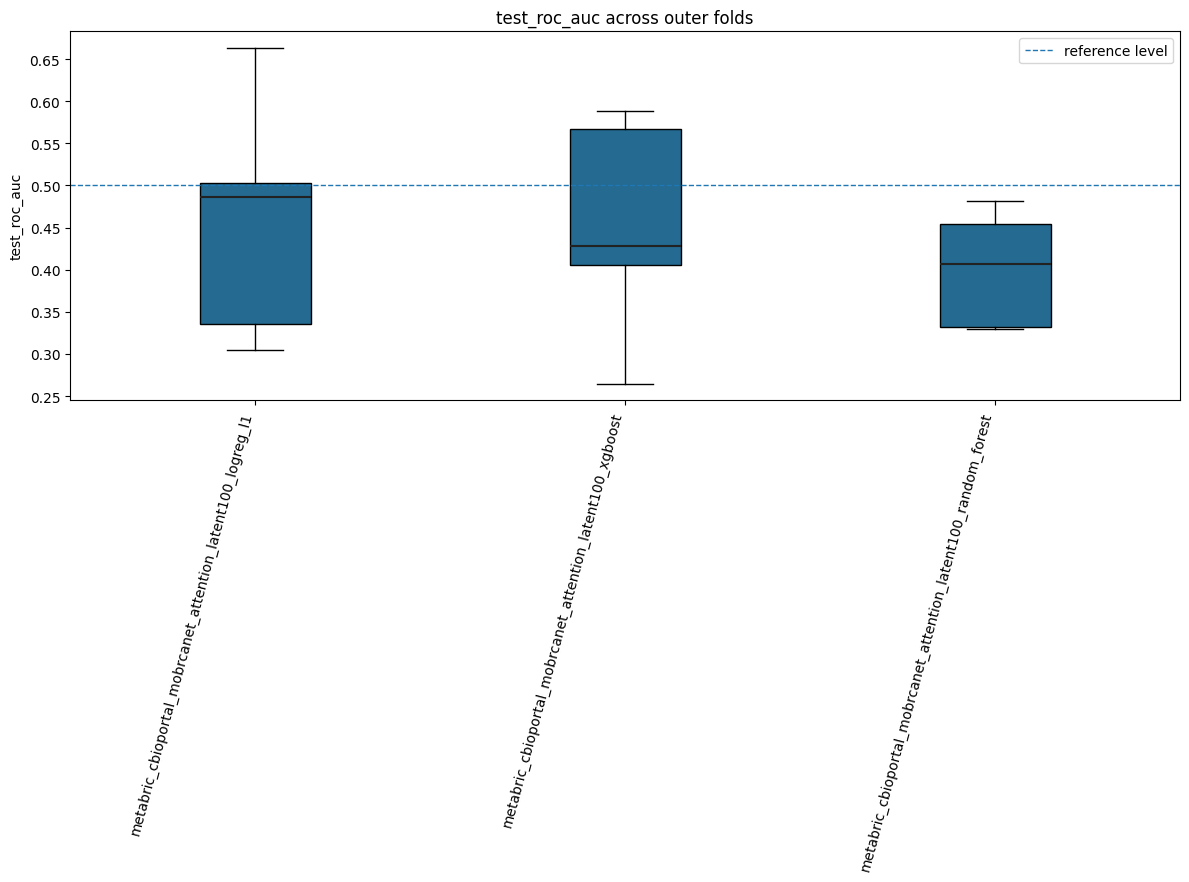

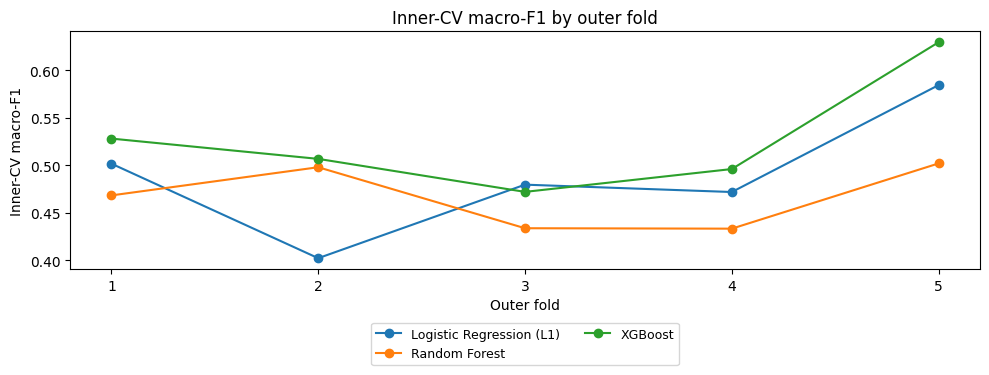

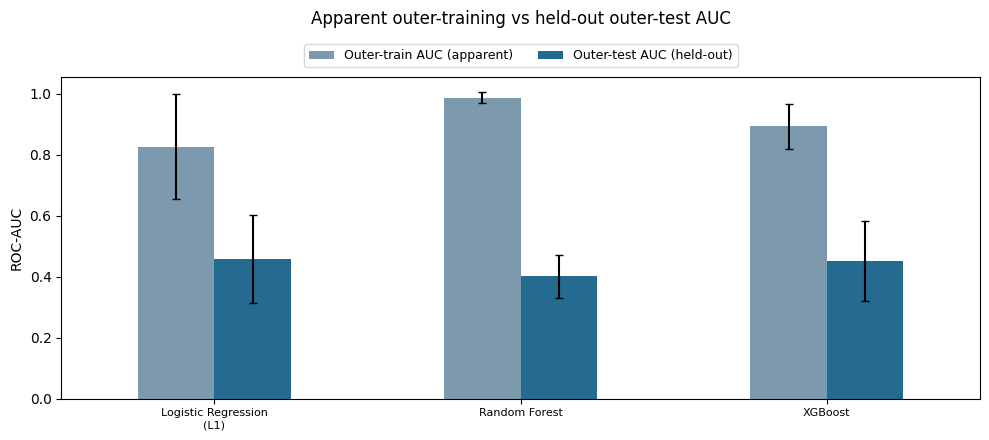

Grouped bars show the preserved mean AUC across five outer folds; error bars show the saved SD. Outer-train AUC is resubstitution (apparent) performance on patients used to fit each outer-fold model; outer-test AUC is held-out performance. Their separation is an overfitting diagnostic.

In [21]:
all_results = attention_results
all_predictions = attention_predictions
selected_combination = None
if len(all_results) == 3 and set(all_results) == set(attention_registry):
    all_metabric_representation_results_df = pd.concat(all_results.values(), ignore_index=True)
    inner_rankings_df, inner_wins_df = rank_tpm_inner_scores(all_metabric_representation_results_df, list(attention_registry))
    validated_oof = {name: validate_tpm_oof(all_predictions[name], name, metadata_df, y, outer_splits) for name in all_results}
    for name, frame in validated_oof.items():
        extra = all_results[name][['outer_fold', 'best_inner_score', 'best_params']]
        validated_oof[name] = frame.drop(columns=['best_inner_score', 'best_params'], errors='ignore').merge(extra, on='outer_fold', validate='many_to_one')
    pooled_oof_df = pd.DataFrame([{"representation": name, **tpm_pooled_oof_metrics(frame)} for name, frame in validated_oof.items()]).set_index("representation")
    summary_df = summarise_representation_results(all_metabric_representation_results_df)
    summary_df = summary_df.join(inner_rankings_df.groupby('representation')['rank'].mean().rename('mean_rank')).join(inner_wins_df)
    selected_combination = select_mean_inner_combination(summary_df)
    all_metabric_representation_results_df['train_test_auc_gap'] = all_metabric_representation_results_df.train_roc_auc - all_metabric_representation_results_df.test_roc_auc
    fold_metric_cols = [c for c in all_metabric_representation_results_df if c.startswith(("train_", "test_"))]
    fold_summary_df = all_metabric_representation_results_df.groupby("representation")[fold_metric_cols].agg(["mean", "std"])
    for stem, frame, use_index in [
        ("all_nested_cv_results", all_metabric_representation_results_df, False),
        ("all_oof_predictions", pd.concat(validated_oof.values(), ignore_index=True), False),
        ("model_selection_summary", summary_df, True), ("fold_metrics_mean_sd", fold_summary_df, True),
        ("pooled_oof_metrics", pooled_oof_df, True), ("inner_fold_rankings", inner_rankings_df, False),
        ("inner_fold_win_counts", inner_wins_df, True)]:
        frame.to_csv(output_dir / f"attention_{stem}_reviewed.csv", index=use_index)
    sampler_rows = []
    for row in all_metabric_representation_results_df.itertuples():
        params = json.loads(row.best_params)
        sampler_rows.append(dict(representation=row.representation, outer_fold=row.outer_fold, sampler=params.get('sampler', 'passthrough'), class_weight=params.get('classifier__class_weight'), scale_pos_weight=params.get('classifier__scale_pos_weight', 1)))
    sampler_summary = pd.DataFrame(sampler_rows)
    sampler_summary.to_csv(output_dir / 'attention_sampler_weighting_reviewed.csv', index=False)
    thesis_display(sampler_summary)
    thesis_display(summary_df, pooled_oof_df, fold_summary_df, inner_rankings_df, inner_wins_df)
    thesis_print("Selected by mean inner-CV macro-F1:", selected_combination)
    plot_metric_boxplots(all_metabric_representation_results_df, metric="test_roc_auc", top_n=3, chance_level=0.5)
    plot_latent_outer_scores(all_metabric_representation_results_df.pivot(index="outer_fold", columns="representation", values="best_inner_score"))
    plt.show()
    train_test_means = all_metabric_representation_results_df.groupby("representation")[["train_roc_auc", "test_roc_auc"]].mean()
    train_test_means["train_test_gap"] = train_test_means.train_roc_auc - train_test_means.test_roc_auc
    train_test_means.to_csv(output_dir / "attention_train_test_comparison_reviewed.csv")
    train_test_sd = all_metabric_representation_results_df.assign(train_test_gap=all_metabric_representation_results_df.train_test_auc_gap).groupby('representation')[['train_roc_auc', 'test_roc_auc', 'train_test_gap']].std()
    plot_latent_train_test(train_test_means, train_test_sd)
    plt.tight_layout(); plt.show()
else:
    thesis_print("Complete canonical results for all three families are required for global selection.")
display(Markdown('Grouped bars show the preserved mean AUC across five outer folds; error bars show the saved SD. Outer-train AUC is resubstitution (apparent) performance on patients used to fit each outer-fold model; outer-test AUC is held-out performance. Their separation is an overfitting diagnostic.'))


## Model selection and held-out performance

XGBoost was selected by the highest mean inner-CV macro-F1: 0.526531 ± 0.060962, versus 0.488055 for L1 logistic regression and 0.467171 for Random Forest. XGBoost had mean inner-score rank 1.2 and won four of five folds, but neither fold wins nor outer-test metrics determined selection. L1's slightly higher mean outer AUC does not justify retrospectively changing the chosen family.

For XGBoost, mean outer ROC-AUC was 0.450695 and balanced accuracy was 0.456578. Mean training ROC-AUC was 0.892490, giving a train–test gap of 0.441795 consistent with substantial overfitting. L1 and Random Forest also showed large gaps (0.368277 and 0.585955); their mean outer AUCs were 0.458503 and 0.400642, respectively.

Selected-model pooled OOF ROC-AUC was 0.464815, balanced accuracy 0.456645 and macro-F1 0.455191. Precision was 0.573333, sensitivity 0.505882 and specificity 0.407407; average precision was 0.585116 and Brier score was 0.253606. These results do not indicate useful held-out discrimination. An AUC below 0.5 is not evidence of meaningful inverse biological prediction. Fold summaries and pooled metrics are complementary, and calibration remains uncertain with 139 patients.


--- Plotting ROC Curve ---


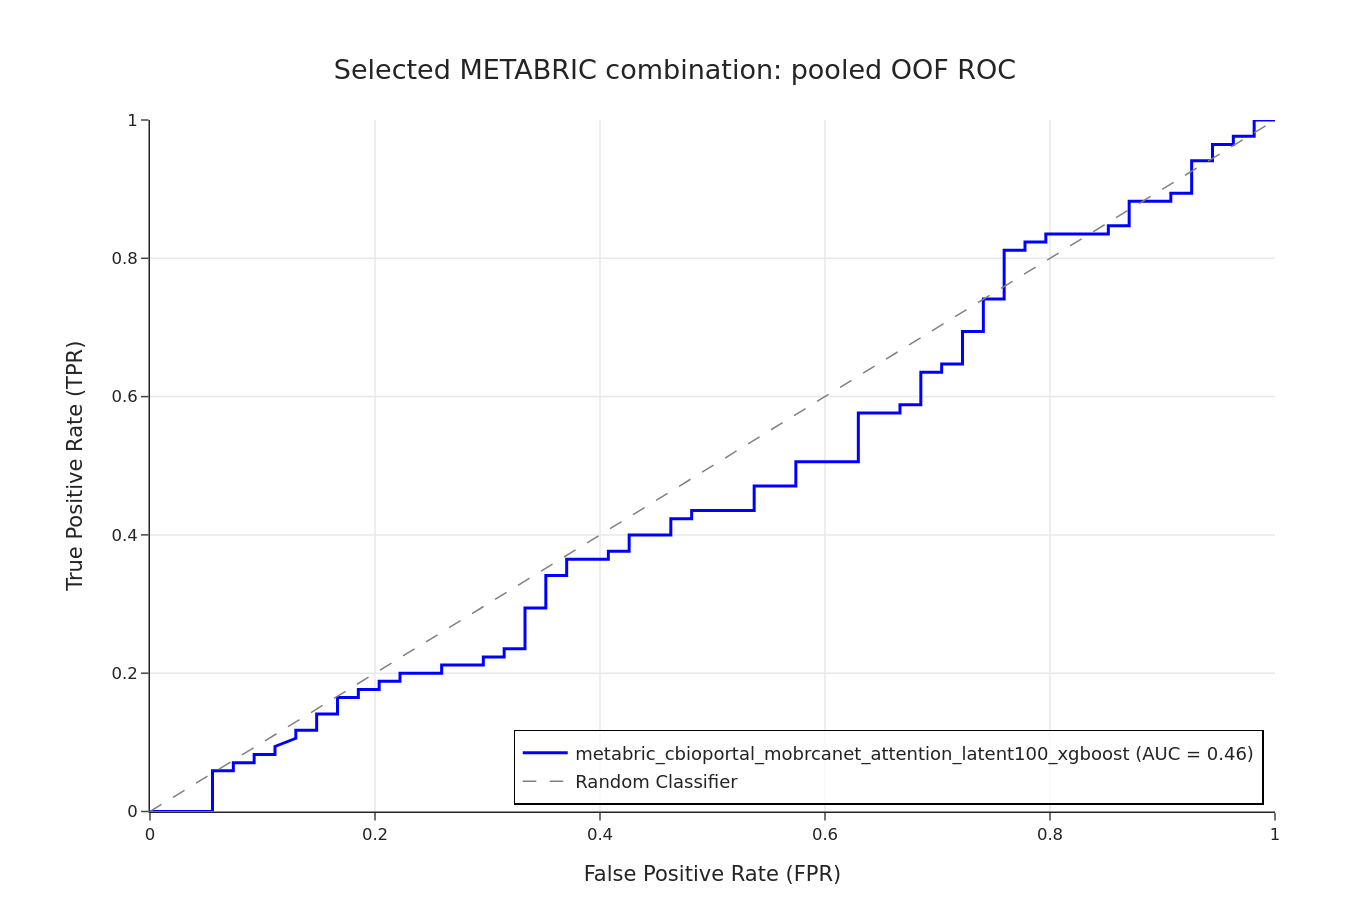

--- Plotting Precision–Recall Curve ---


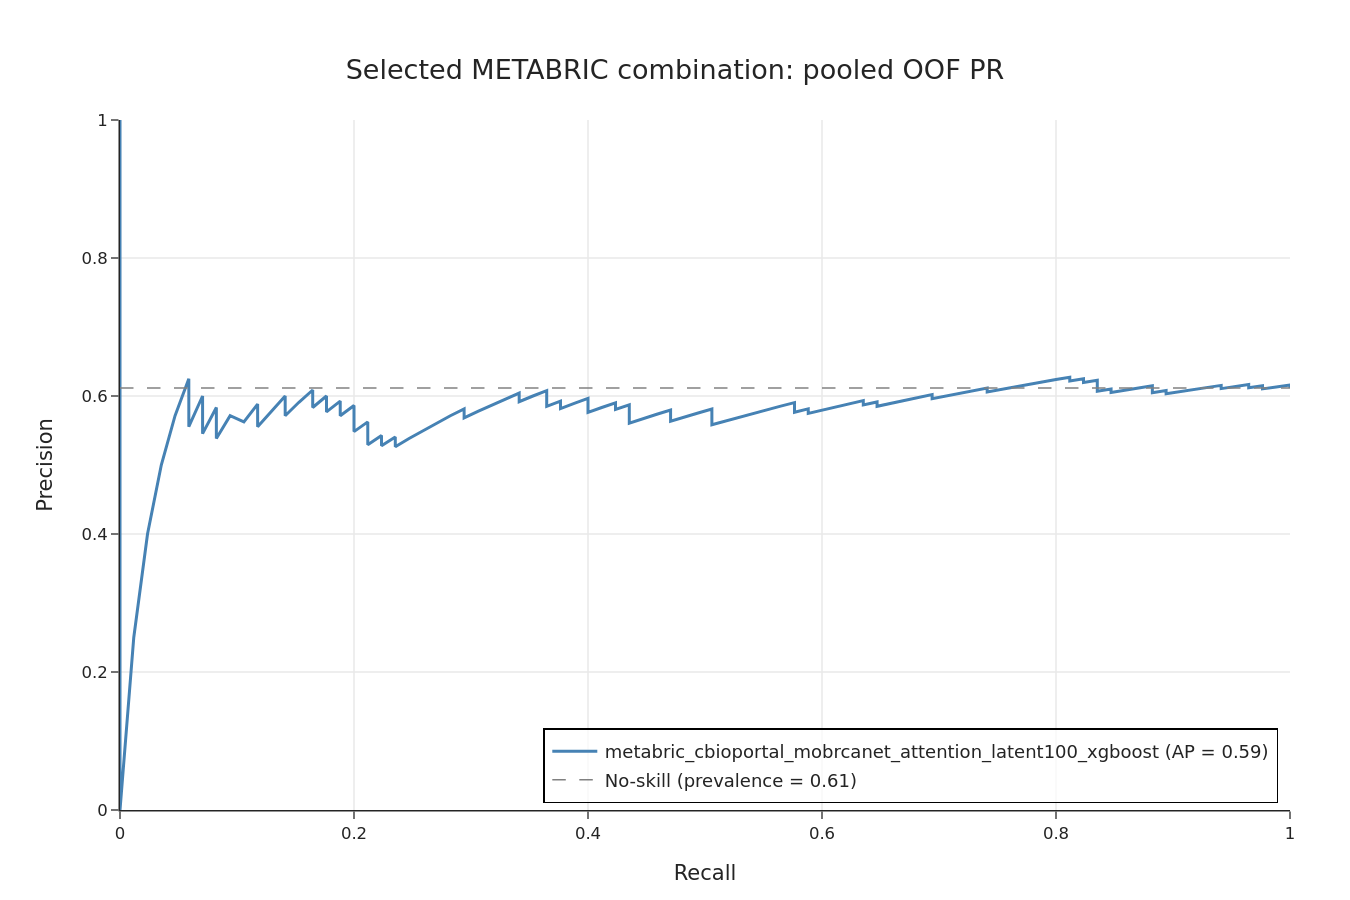

--- Plotting Confusion Matrix ---


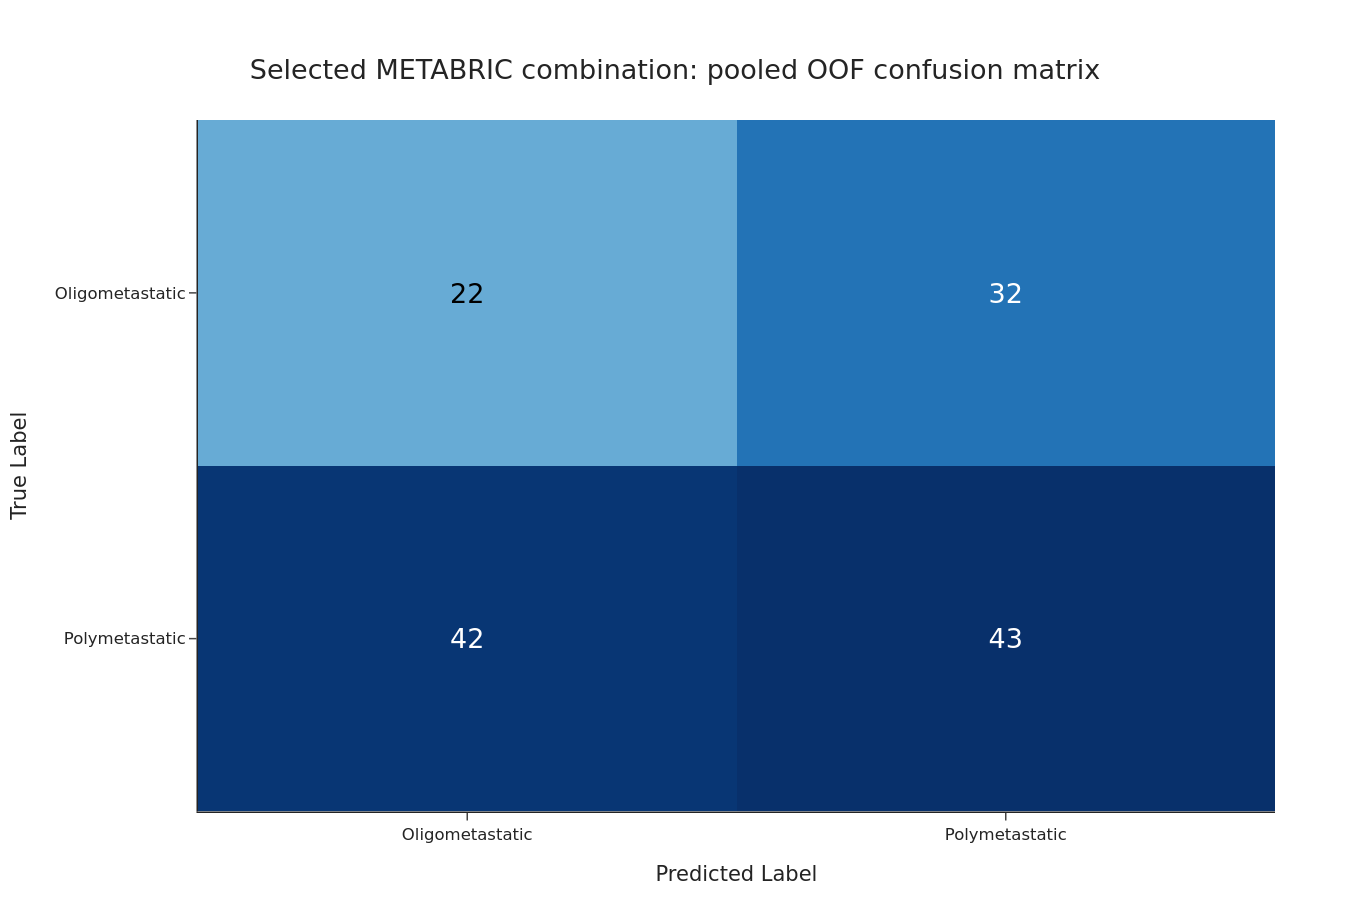

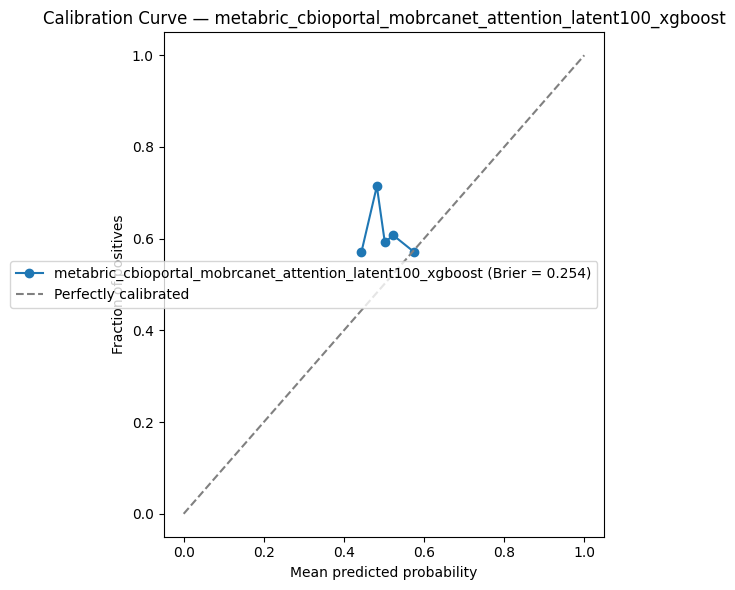

Pooled OOF Brier score: 0.254


In [22]:
if selected_combination is not None:
    selected_predictions_df = validated_oof[selected_combination]
    curve = [{"y_true": selected_predictions_df.y_true.to_numpy(), "y_prob": selected_predictions_df.y_prob_poly.to_numpy(), "label": selected_combination, "is_main_curve": True}]
    plot_roc_curves(curve, title="Selected METABRIC combination: pooled OOF ROC", interactive=False)
    plot_precision_recall_curves(curve, title="Selected METABRIC combination: pooled OOF PR", interactive=False)
    plot_confusion_matrix(selected_predictions_df.y_true, selected_predictions_df.y_pred,
        class_labels=["Oligometastatic", "Polymetastatic"], title="Selected METABRIC combination: pooled OOF confusion matrix", interactive=False)
    brier = plot_calibration_curve(selected_predictions_df.rename(columns={"representation": "model", "y_prob_poly": "y_proba"}), selected_combination, n_bins=5)
    thesis_print("Pooled OOF Brier score:", brier)


## Representation diagnostics

UMAP and label-based silhouette scores describe the frozen institutional representation post hoc. Neither is used for selection or tuning.


{'representation': 'metabric_cbioportal_mobrcanet_attention_latent100',
 'silhouette_score': -5.42e-4,
 'n_samples': 139,
 'n_features': 100}

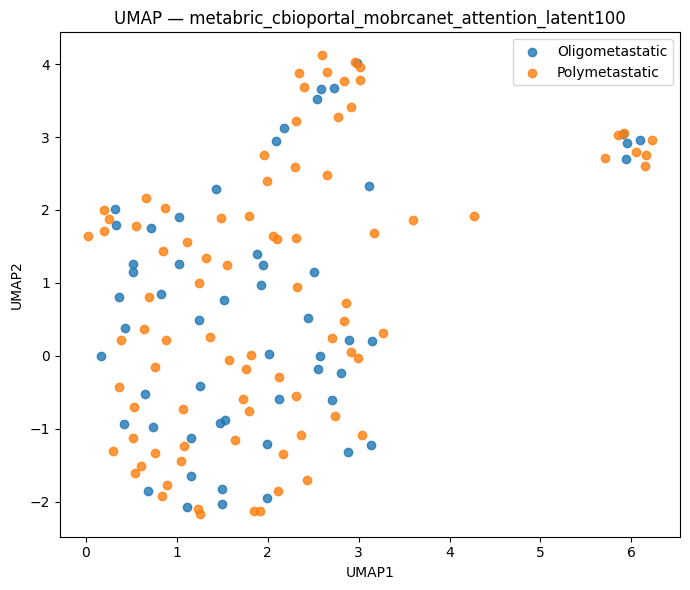

In [2]:
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message=r"^n_jobs value 1 overridden to 1 by setting random_state\. Use no seed for parallelism\.$",
        category=UserWarning,
        module=r"^umap\.umap_$",
    )
    if RUN_EXPLORATORY:
        if X_repr is None: raise ValueError('Canonical scores required')
        thesis_display(compute_representation_silhouette(X_repr, y_repr, REPRESENTATION_NAME, scale=True))
        plot_umap_representation(X_repr, y_repr, REPRESENTATION_NAME, random_state=42, scale=True)


> **Supplementary FLAML analysis.** These FLAML (AutoML) results are retained as a supplementary analysis and are not reported in the submitted thesis. 

## Aligned FLAML comparator

FLAML used the same outer splits and complete inner-fitting pipelines, five stratified inner folds, macro-F1, seed 42 and 120 seconds per outer fold. Mean inner macro-F1 was 0.529692 and mean outer ROC-AUC was 0.451658. Pooled OOF ROC-AUC was 0.460566, balanced accuracy 0.451634 and macro-F1 0.446795. Precision was 0.565217, sensitivity 0.458824, specificity 0.444444, average precision 0.595866 and Brier score 0.253811.

Automated search therefore did not change the conclusion of weak held-out prediction. Its inner score does not replace the prespecified manual family selection. The separate full-cohort FLAML search selected metabric_latent_xgboost with inner score 0.508094; this model is also used only for interpretation.

FLAML receives an explicit `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` for inner validation, as does the manual search. The same ordered outer-training inputs therefore define the same inner-fold membership in the current implementation; FLAML may permute training-row order within a fold. Saved patient-level predictions confirm identical outer-test assignments.


In [25]:
fixed_representations = {} if X_repr is None else {REPRESENTATION_NAME: (X_repr, y_repr)}
flaml_results = {}
if RUN_FLAML and len(fixed_representations) != 1:
    raise ValueError("The canonical fixed representation is required for aligned FLAML.")
for representation, (features, labels) in fixed_representations.items():
    name = representation + "_flaml"
    paths = [output_dir / f"{name}_{kind}_aligned.csv" for kind in ["nested_test", "nested_train", "oof_predictions"]]
    score_path = latent_scores_path
    score_fingerprint = metabric_source_fingerprint([score_path])
    flaml_manifest_path = output_dir / f"{name}_provenance_aligned.json"
    if RUN_FLAML:
        test, train, oof = run_nested_flaml_metabric_latent(features, labels, name, metadata_df, outer_splits, FLAML_TIME_BUDGET_SECONDS, RANDOM_STATE, configs=attention_configs)
        for frame, dest in zip([test, train, oof], paths): frame.to_csv(dest, index=False)
        flaml_manifest_path.write_text(json.dumps({"score_source": score_fingerprint}, indent=2))
    elif all(p.exists() for p in paths):
        if json.loads(flaml_manifest_path.read_text()).get("score_source") != score_fingerprint:
            raise ValueError("Cached FLAML results belong to another encoder score file.")
        test, train, oof = [pd.read_csv(p) for p in paths]
    elif any(p.exists() for p in paths):
        raise ValueError("Incomplete aligned FLAML result bundle.")
    else:
        continue
    for frame in [test, train]:
        if len(frame) != 5 or set(frame.outer_fold) != set(range(1, 6)):
            raise ValueError("Five unique FLAML outer-fold results required.")
    protocol = pd.concat([test, train, oof], ignore_index=True)
    if not protocol.inner_n_splits.eq(5).all() or not protocol.selection_metric.eq("macro_f1").all():
        raise ValueError("Saved FLAML protocol is not aligned.")
    if protocol.time_budget_seconds.nunique() != 1 or (FLAML_TIME_BUDGET_SECONDS is not None and not protocol.time_budget_seconds.eq(FLAML_TIME_BUDGET_SECONDS).all()):
        raise ValueError("FLAML budget mismatch.")
    oof = validate_tpm_oof(oof, name, metadata_df, y, outer_splits)
    pooled = {"representation": name, **tpm_pooled_oof_metrics(oof), "mean_inner_cv_score": test.best_inner_score.mean(), "mean_outer_roc_auc": test.roc_auc.mean()}
    pd.DataFrame([pooled]).to_csv(output_dir / f"{name}_pooled_oof_metrics_aligned.csv", index=False)
    flaml_results[representation] = {"test": test, "train": train, "oof": oof, "pooled": pooled}
    flaml_metric_cols = list(tpm_pooled_oof_metrics(oof)) + ["best_inner_score"]
    flaml_fold_summary = pd.concat([train, test]).groupby("dataset")[flaml_metric_cols].agg(["mean", "std"])
    flaml_fold_summary.to_csv(output_dir / f"{name}_fold_metrics_mean_sd_aligned.csv")
    thesis_display(test, train, pd.DataFrame([pooled]), flaml_fold_summary)
if selected_combination is not None and len(flaml_results) == 1:
    manual_comparison = pooled_oof_df.join(summary_df[["mean_inner_cv_score", "mean_test_roc_auc"]]).rename(columns={"mean_test_roc_auc": "mean_outer_roc_auc"})
    comparison = pd.concat([manual_comparison.reset_index(), pd.DataFrame([v["pooled"] for v in flaml_results.values()])], ignore_index=True)
    comparison.to_csv(output_dir / "attention_manual_vs_flaml_aligned.csv", index=False)
    thesis_display(comparison)


,representation,outer_fold,best_inner_score,best_params,selection_metric,inner_n_splits,time_budget_seconds,dataset,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
0,metabric_cbioportal_mobrcanet_attention_latent...,1,0.506,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.591,0.465,0.426,0.556,0.294,0.636,0.672,0.250
1,metabric_cbioportal_mobrcanet_attention_latent...,2,0.535,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.393,0.444,0.427,0.571,0.706,0.182,0.557,0.258
2,metabric_cbioportal_mobrcanet_attention_latent...,3,0.489,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.396,0.465,0.426,0.556,0.294,0.636,0.594,0.255
3,metabric_cbioportal_mobrcanet_attention_latent...,4,0.501,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.508,0.505,0.505,0.611,0.647,0.364,0.635,0.245
4,metabric_cbioportal_mobrcanet_attention_latent...,5,0.619,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.371,0.376,0.367,0.500,0.353,0.400,0.627,0.262


,representation,outer_fold,best_inner_score,best_params,selection_metric,inner_n_splits,time_budget_seconds,dataset,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
0,metabric_cbioportal_mobrcanet_attention_latent...,1,0.506,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.783,0.687,0.678,0.780,0.676,0.698,0.855,0.226
1,metabric_cbioportal_mobrcanet_attention_latent...,2,0.535,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.944,0.863,0.866,0.886,0.912,0.814,0.961,0.196
2,metabric_cbioportal_mobrcanet_attention_latent...,3,0.489,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.835,0.729,0.694,0.886,0.574,0.884,0.899,0.241
3,metabric_cbioportal_mobrcanet_attention_latent...,4,0.501,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.900,0.813,0.817,0.845,0.882,0.744,0.928,0.196
4,metabric_cbioportal_mobrcanet_attention_latent...,5,0.619,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.768,0.732,0.719,0.825,0.691,0.773,0.825,0.230


,representation,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score,mean_inner_cv_score,mean_outer_roc_auc
0,metabric_cbioportal_mobrcanet_attention_latent...,0.461,0.452,0.447,0.565,0.459,0.444,0.596,0.254,0.530,0.452


roc_auc           balanced_accuracy            f1_macro            \
             mean       std              mean       std      mean       std   
dataset                                                                       
test     0.452  0.094          0.451  0.047  0.430  0.049   
train    0.846  0.075          0.765  0.071  0.755  0.082   

        precision              recall           specificity            \
             mean       std      mean       std        mean       std   
dataset                                                                 
test     0.559  0.040  0.459  0.201    0.444  0.194   
train    0.844  0.045  0.747  0.145    0.782  0.071   

        average_precision           brier_score           best_inner_score  \
                     mean       std        mean       std             mean   
dataset                                                                      
test             0.617  0.043    0.254  0.007         0.530   
train            0.894  0.055    0.218  0.021         0.530   

                   
              std  
dataset            
test     0.052  
train    0.052

,representation,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score,mean_inner_cv_score,mean_outer_roc_auc
0,metabric_cbioportal_mobrcanet_attention_latent...,0.481,0.484,0.480,0.597,0.506,0.463,0.615,0.311,0.488,0.459
1,metabric_cbioportal_mobrcanet_attention_latent...,0.410,0.425,0.416,0.561,0.647,0.204,0.581,0.255,0.467,0.401
2,metabric_cbioportal_mobrcanet_attention_latent...,0.465,0.457,0.455,0.573,0.506,0.407,0.585,0.254,0.527,0.451
3,metabric_cbioportal_mobrcanet_attention_latent...,0.461,0.452,0.447,0.565,0.459,0.444,0.596,0.254,0.530,0.452


In [26]:
if RUN_FULL_COHORT_FLAML:
    if selected_combination is None:
        raise ValueError("Freeze manual selection before full-cohort FLAML interpretation.")
    selected_config = attention_registry[selected_combination]
    representation = selected_config["representation"]
    if representation not in flaml_results or not flaml_results[representation]["test"].time_budget_seconds.eq(FLAML_TIME_BUDGET_SECONDS).all():
        raise ValueError("Load/run aligned nested FLAML using the same common budget first.")
    full_automl = fit_metabric_latent_flaml(selected_config["X"], selected_config["y"], FLAML_TIME_BUDGET_SECONDS, RANDOM_STATE, configs=attention_configs)
    flaml_ranking = extract_fitted_tpm_feature_rankings(full_automl.model.estimator, selected_config["X"].columns)
    flaml_ranking.to_csv(output_dir / f"{representation}_flaml_latent_ranking_full_cohort_tuned.csv", index=False)
    (output_dir / f"{representation}_flaml_params_full_cohort_tuned.json").write_text(json.dumps({
        "best_estimator": full_automl.best_estimator, "best_config": full_automl.best_config,
        "best_inner_score": 1-full_automl.best_loss, "n_splits": 5, "metric": "macro_f1",
        "time_budget_seconds": FLAML_TIME_BUDGET_SECONDS, "interpretation_only": True}, indent=2, default=str))
    display_interpretation(flaml_ranking.head(20))


,feature,importance,feature_score,rank
0,Latent 18,0.0774,0.077,1
1,Latent 91,0.0597,0.060,2
2,Latent 50,0.0593,0.059,3
3,Latent 47,0.0566,0.057,4
4,Latent 94,0.0547,0.055,5
5,Latent 58,0.0506,0.051,6
6,Latent 55,0.0491,0.049,7
7,Latent 3,0.0482,0.048,8
8,Latent 75,0.0481,0.048,9
9,Latent 25,0.0459,0.046,10


## Scientific conclusion

The METABRIC-trained moBRCA-net-inspired attention representation did not generalise reliably for oligo/poly prediction in this cohort. Poor held-out discrimination and large train–test gaps indicate substantial overfitting. External subtype supervision, cross-platform transfer and the small institutional cohort may limit transfer to this endpoint, but their individual contributions were not isolated. Nor do these findings show that biological structure is absent.
